In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex

#import csv

import numpy as np

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.general.analysis import Add_Columns_To_Dataframe
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.impedance.analysis import Restructure_Dataframe_By_Frequency
from scientific_utils.impedance.plotting import Matplotlib_XvsY_And_Frequency_Extraction

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the .pkl file ########

##### OCVs after a Charging step in the C Rate Test
#with open('./data/processed/list_of_dataframes_of_OCV_charge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_charge = pickle.load(f)

##### OCVs after a Discharging step in the C Rate Test
#with open('./data/processed/list_of_dataframes_of_OCV_discharge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_discharge = pickle.load(f)    

##### Impedance spectra after a Charging step in the C Rate Test
with open('./data/processed/list_of_dataframes_of_PEIS_charge.pkl', 'rb') as f:
    list_of_dataframes_of_PEIS_charge = pickle.load(f)      
    
##### Impedance spectra after a Discharging step in the C Rate Test
with open('./data/processed/list_of_dataframes_of_PEIS_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_PEIS_discharge = pickle.load(f)    

#print(list_of_dataframes_of_PEIS_discharge)

########## Create a list with more information about the data for plotting later #######
list_RateTest_labels = [0.10, 0.33, 1.00, 5, 5]


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 3 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    #"pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    "pgf.rcfonts": True,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
###################################### Definition of Functions ###############################

In [9]:
# Deleting unneccesary Data of CP charge
#list_of_dataframes = list_of_dataframes_of_PEIS_charge

#list_of_dataframes_of_PEIS_charge_cleaned = DeleteListEntries(list_of_dataframes)
list_of_dataframes_of_PEIS_charge_cleaned = list_of_dataframes_of_PEIS_charge
#print(list_of_dataframes_of_CP_charge_equidistant_cleaned)


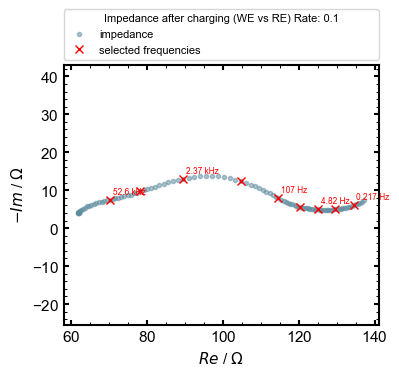

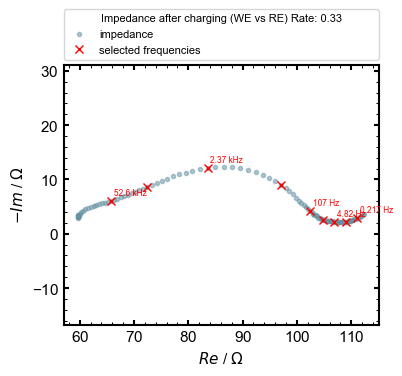

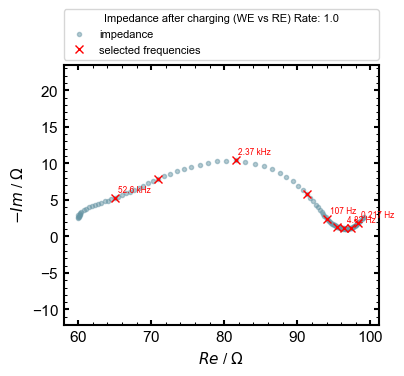

In [10]:
list_of_dataframes = list_of_dataframes_of_PEIS_charge_cleaned
x_values_column_name = 'Re(Z)/Ohm'
y_values_column_name = '-Im(Z)/Ohm'
z_values_column_name = 'freq/Hz'
y_ax_label = r'$-Im $ / $\Omega $'
x_ax_label = r'$Re $ / $\Omega $'
rate_to_save = 3
additional_name = 'charge'
legend_title = 'Impedance after charging (WE vs RE)'

result_charge = Matplotlib_XvsY_And_Frequency_Extraction(list_of_dataframes, x_values_column_name, y_values_column_name, z_values_column_name, y_ax_label, x_ax_label, rate_to_save, additional_name, legend_title, list_RateTest_labels)

result_charge[0]

dataframe_of_selected_frequencies_charge_rates = result_charge[1]

In [11]:
display(dataframe_of_selected_frequencies_charge_rates)

,Real / Ohm at Frequency 52618.391 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 52618.391 Hz and Rate 0.1 C,Real / Ohm at Frequency 11171.318 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 11171.318 Hz and Rate 0.1 C,Real / Ohm at Frequency 2370.76 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 2370.76 Hz and Rate 0.1 C,Real / Ohm at Frequency 503.55 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 503.55 Hz and Rate 0.1 C,Real / Ohm at Frequency 106.881 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 106.881 Hz and Rate 0.1 C,...,Real / Ohm at Frequency 106.881 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 106.881 Hz and Rate 1.0 C,Real / Ohm at Frequency 22.684 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 22.684 Hz and Rate 1.0 C,Real / Ohm at Frequency 4.817 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 4.817 Hz and Rate 1.0 C,Real / Ohm at Frequency 1.022 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 1.022 Hz and Rate 1.0 C,Real / Ohm at Frequency 0.217 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 0.217 Hz and Rate 1.0 C
0,70.169624,7.498917,78.241028,9.687042,89.464455,13.003917,104.70233,12.463906,114.59795,7.908601,...,94.064476,2.338288,95.385368,1.345839,96.371628,1.081634,97.285202,1.12942,98.329414,1.856412


In [12]:
# Deleting unneccesary Data of CP charge
#list_of_dataframes = list_of_dataframes_of_PEIS_discharge

#list_of_dataframes_of_PEIS_discharge_cleaned = DeleteListEntries(list_of_dataframes)
list_of_dataframes_of_PEIS_discharge_cleaned = list_of_dataframes_of_PEIS_discharge
#print(list_of_dataframes_of_CP_charge_equidistant_cleaned)

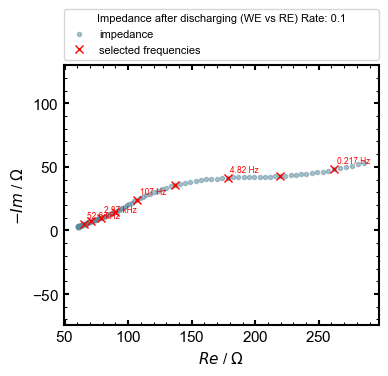

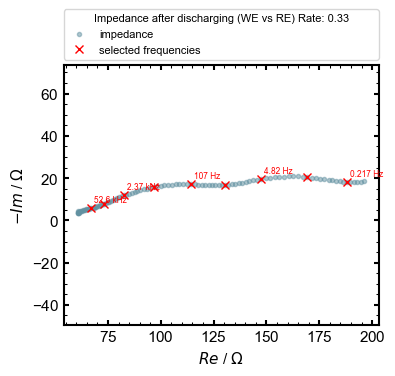

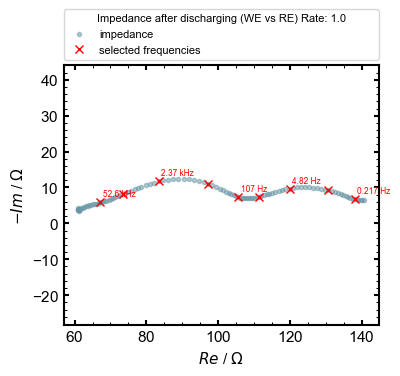

In [13]:
list_of_dataframes = list_of_dataframes_of_PEIS_discharge_cleaned
x_values_column_name = 'Re(Z)/Ohm'
y_values_column_name = '-Im(Z)/Ohm'
z_values_column_name = 'freq/Hz'
y_ax_label = r'$-Im $ / $\Omega$ '
x_ax_label = r'$Re $ / $\Omega$ '
rate_to_save = 3
additional_name = 'discharge'
legend_title = 'Impedance after discharging (WE vs RE)'

result_discharge = Matplotlib_XvsY_And_Frequency_Extraction(list_of_dataframes, x_values_column_name, y_values_column_name, z_values_column_name, y_ax_label, x_ax_label, rate_to_save, additional_name, legend_title, list_RateTest_labels)

result_discharge[0]

dataframe_of_selected_frequencies_discharge_rates = result_discharge[1]

In [14]:
display(dataframe_of_selected_frequencies_discharge_rates)

,Real / Ohm at Frequency 52618.391 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 52618.391 Hz and Rate 0.1 C,Real / Ohm at Frequency 11171.318 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 11171.318 Hz and Rate 0.1 C,Real / Ohm at Frequency 2370.76 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 2370.76 Hz and Rate 0.1 C,Real / Ohm at Frequency 503.55 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 503.55 Hz and Rate 0.1 C,Real / Ohm at Frequency 106.881 Hz and Rate 0.1 C,-Imag / Ohm at Frequency 106.881 Hz and Rate 0.1 C,...,Real / Ohm at Frequency 106.881 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 106.881 Hz and Rate 1.0 C,Real / Ohm at Frequency 22.684 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 22.684 Hz and Rate 1.0 C,Real / Ohm at Frequency 4.817 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 4.817 Hz and Rate 1.0 C,Real / Ohm at Frequency 1.022 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 1.022 Hz and Rate 1.0 C,Real / Ohm at Frequency 0.217 Hz and Rate 1.0 C,-Imag / Ohm at Frequency 0.217 Hz and Rate 1.0 C
0,65.392502,4.846713,70.820427,6.996348,78.875572,10.105003,89.943047,14.693494,106.99752,23.918835,...,105.48889,7.300832,111.37555,7.39272,119.91992,9.692415,130.74197,9.200957,138.01967,6.807371


In [15]:
################### Saving frequencies in dataframe for multivariate analysis

In [16]:
# Saving only the selected frequncies in one dataframe
new_columns = {} # the values are collected first and added at once (adding the columns one by one fragments the dataframe)

# Create an empty dataframe for the data
dataframe_with_all_extracted_data_from_Rate_Test_Impedance = pd.DataFrame() # creating new empty dataframe
    
with open('./data/processed/dataframe_with_all_extracted_data_from_Rate_Test_Impedance.pkl', 'wb') as f:
    pickle.dump(dataframe_with_all_extracted_data_from_Rate_Test_Impedance, f)

### charging steps of the rate test
for i in range(0, len(dataframe_of_selected_frequencies_charge_rates.columns)):
    column_name = dataframe_of_selected_frequencies_charge_rates.columns[i]
    new_columns[column_name  + ' charge step'] = dataframe_of_selected_frequencies_charge_rates.loc[0, column_name]
    
### discharging steps of the rate test
for i in range(0, len(dataframe_of_selected_frequencies_discharge_rates.columns)):
    column_name = dataframe_of_selected_frequencies_discharge_rates.columns[i]
    new_columns[column_name + ' discharge step'] = dataframe_of_selected_frequencies_discharge_rates.loc[0, column_name]

dataframe_with_all_extracted_data_from_Rate_Test_Impedance = Add_Columns_To_Dataframe(dataframe_with_all_extracted_data_from_Rate_Test_Impedance, new_columns)

In [17]:
display(dataframe_with_all_extracted_data_from_Rate_Test_Impedance)

,Real / Ohm at Frequency 52618.391 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 52618.391 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 11171.318 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 11171.318 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 2370.76 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 2370.76 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 503.55 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 503.55 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 106.881 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 106.881 Hz and Rate 0.1 C charge step,...,Real / Ohm at Frequency 106.881 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 106.881 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 22.684 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 22.684 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 4.817 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 4.817 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 1.022 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 1.022 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 0.217 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 0.217 Hz and Rate 1.0 C discharge step
0,70.169624,7.498917,78.241028,9.687042,89.464455,13.003917,104.70233,12.463906,114.59795,7.908601,...,105.48889,7.300832,111.37555,7.39272,119.91992,9.692415,130.74197,9.200957,138.01967,6.807371


In [18]:
# Saving all frequqncies in one dataframe
new_columns = {} # the values are collected first and added at once (adding the columns one by one fragments the dataframe)

list_of_dataframes = list_of_dataframes_of_PEIS_charge_cleaned 
x_values_column_name = 'Re(Z)/Ohm'
y_values_column_name = '-Im(Z)/Ohm'
z_values_column_name = 'freq/Hz'

dataframe_of_all_frequencies_charge_rates = Restructure_Dataframe_By_Frequency(list_of_dataframes, x_values_column_name, y_values_column_name, z_values_column_name, list_RateTest_labels)
    

list_of_dataframes = list_of_dataframes_of_PEIS_discharge_cleaned 
x_values_column_name = 'Re(Z)/Ohm'
y_values_column_name = '-Im(Z)/Ohm'
z_values_column_name = 'freq/Hz'

dataframe_of_all_frequencies_discharge_rates = Restructure_Dataframe_By_Frequency(list_of_dataframes, x_values_column_name, y_values_column_name, z_values_column_name, list_RateTest_labels)

# Create an empty dataframe for the data
dataframe_with_all_data_from_Rate_Test_Impedance = pd.DataFrame() # creating new empty dataframe
    
with open('./data/processed/dataframe_with_all_data_from_Rate_Test_Impedance.pkl', 'wb') as f:
    pickle.dump(dataframe_with_all_data_from_Rate_Test_Impedance, f)

### charging steps of the rate test
for i in range(0, len(dataframe_of_all_frequencies_charge_rates.columns)):
    column_name = dataframe_of_all_frequencies_charge_rates.columns[i]
    new_columns[column_name  + ' charge step'] = dataframe_of_all_frequencies_charge_rates.loc[0, column_name]
    
### discharging steps of the rate test
for i in range(0, len(dataframe_of_all_frequencies_discharge_rates.columns)):
    column_name = dataframe_of_all_frequencies_discharge_rates.columns[i]
    new_columns[column_name + ' discharge step'] = dataframe_of_all_frequencies_discharge_rates.loc[0, column_name]

dataframe_with_all_data_from_Rate_Test_Impedance = Add_Columns_To_Dataframe(dataframe_with_all_data_from_Rate_Test_Impedance, new_columns)

In [19]:
with open('./data/processed/dataframe_with_all_data_from_Rate_Test_Impedance.pkl', 'wb') as f:
    pickle.dump(dataframe_with_all_data_from_Rate_Test_Impedance, f)
    
display(dataframe_with_all_data_from_Rate_Test_Impedance)

,Real / Ohm at Frequency 1000018.6 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 1000018.6 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 856433.69 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 856433.69 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 733475.0 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 733475.0 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 628173.25 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 628173.25 Hz and Rate 0.1 C charge step,Real / Ohm at Frequency 537986.19 Hz and Rate 0.1 C charge step,-Imag / Ohm at Frequency 537986.19 Hz and Rate 0.1 C charge step,...,Real / Ohm at Frequency 0.186 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 0.186 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 0.159 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 0.159 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 0.136 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 0.136 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 0.117 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 0.117 Hz and Rate 1.0 C discharge step,Real / Ohm at Frequency 0.1 Hz and Rate 1.0 C discharge step,-Imag / Ohm at Frequency 0.1 Hz and Rate 1.0 C discharge step
0,61.75449,4.321906,61.872715,4.075503,61.855942,3.999505,61.922909,3.965646,62.039608,4.047206,...,138.57448,6.680565,139.09982,6.60521,139.66011,6.578562,140.17468,6.581989,140.69615,6.605075


In [20]:
# Saving all extracted data
with open('./data/processed/dataframe_of_selected_frequencies_charge_rates.pkl', 'wb') as f:
    pickle.dump(dataframe_of_selected_frequencies_charge_rates, f)
    
with open('./data/processed/dataframe_of_selected_frequencies_discharge_rates.pkl', 'wb') as f:
    pickle.dump(dataframe_of_selected_frequencies_discharge_rates, f)

with open('./data/processed/dataframe_with_all_extracted_data_from_Rate_Test_Impedance.pkl', 'wb') as f:
    pickle.dump(dataframe_with_all_extracted_data_from_Rate_Test_Impedance, f)